# T06 · Linear Regression (Equation · Coefficients · Prediction · MAE/MSE/RMSE/R² · Baseline · เทียบโมเดล regression)

**ใช้เมื่อโจทย์ถาม:** ทำนาย "ตัวเลข" (ราคา, ยอดขาย, ค่าใช้จ่าย) · เขียนสมการ · ตีความ coefficient · R² ·
เทียบกับ mean baseline · simple vs multiple regression · residual plot · ทำนายข้อมูลใหม่ · เทียบ KNN/Tree regressor · optimize

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** — `TARGET` (ตัวเลข), `SIMPLE_X` (ตัวแปรเดียว ถ้าโจทย์ให้ simple regression), `NEW_DATA` |
| 2 | Run All · สมการอยู่ §3–§4 · ตาราง metric อยู่ §5 |

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../practice/data/p7_insurance.csv"
TARGET    = "charges"        # ตัวเลขที่จะทำนาย
ID_COL    = None
DROP_COLS = []
FEATURES  = None             # list feature ที่โจทย์ให้ใช้ · None = ทุกคอลัมน์ที่เหลือ
SIMPLE_X  = "age"            # ตัวแปรเดียวสำหรับ simple linear regression (None = ข้าม §3)
DROP_FIRST = True            # one-hot ตัด dummy ตัวแรก (reference category) → ตีความ coef ง่าย ไม่ซ้ำซ้อน
NEW_DATA  = {"age": 40, "sex": "male", "bmi": 30.0, "children": 2, "smoker": "no", "region": "northeast"}   # None = ข้าม
EVAL_MODE = "holdout"        # "holdout" (train/test) | "cv"
TEST_SIZE, N_FOLDS, SEED = 0.2, 5, 42
MISSING_MARKERS, SHEET, CSV_SEP = ["?", "", " ", "NA"], 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        for enc in ["utf-8-sig", "cp874", "latin1"]:      # utf-8 (ตัด BOM) → ภาษาไทยจาก Excel (cp874) → อื่น ๆ
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc)
                break
            except UnicodeDecodeError:
                continue
        if df.shape[1] == 1 and ";" in str(df.columns[0]):  # ไฟล์คั่นด้วย ; แต่ตั้ง CSV_SEP = ","
            df = pd.read_csv(path, sep=";", encoding=enc)
            print("ℹ️ ไฟล์นี้คั่นด้วย ';' → อ่านใหม่ด้วย sep=';'")
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def fix_col(df, col, kind="any", i=0):
    """คอลัมน์ที่ตั้งไว้ใน ✏️ ไม่มีในข้อมูลนี้ → เลือกคอลัมน์ชนิดเดียวกันให้ชั่วคราว (Run All ไม่หยุด) — ควรแก้ ✏️ ให้ตรงโจทย์
    kind: "num" = ตัวเลขต่อเนื่อง · "cat" = หมวดหมู่ (ค่าไม่เกิน 20 แบบ) · "any" """
    if col is None or col in df.columns:
        return col
    skip = {ID_COL}
    nums = [c for c in num_cols(df) if c not in skip]
    if kind == "num":
        pool = [c for c in nums if df[c].nunique() > 10] or nums
    elif kind == "cat":
        few = [c for c in df.columns if c not in skip and df[c].nunique() <= 20]
        pool = [c for c in few if c not in nums] + [c for c in few if c in nums]
    else:
        pool = [c for c in df.columns if c not in skip]
    new = pool[min(i, len(pool) - 1)] if pool else None
    print(f"⚠️ ไม่มีคอลัมน์ {col!r} ในข้อมูลนี้ → ใช้ {new!r} แทนชั่วคราว (แก้บรรทัด ✏️ ให้ตรงโจทย์)")
    return new


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": float(mean_absolute_error(y_true, y_pred)), "MSE": float(mse), "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_true, y_pred))}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §1 โหลด + EDA ของ target + correlation กับ target

โหลด ../practice/data/p7_insurance.csv → 1338 แถว × 7 คอลัมน์
shape: (1338, 7) | แถวซ้ำ: 1


,dtype,missing,missing_%,unique,example
age,int64,0,0.0000,47,19
sex,str,0,0.0000,2,female
bmi,float64,0,0.0000,548,27.9000
children,int64,0,0.0000,6,0
smoker,str,0,0.0000,2,yes
region,str,0,0.0000,4,southwest
charges,float64,0,0.0000,1337,"16,884.9240"


target 'charges' เป็นตัวเลข (regression):


,count,mean,std,min,25%,50%,75%,max
charges,"1,338.0000","13,270.4223","12,110.0112","1,121.8739","4,740.2872","9,382.0330","16,639.9125","63,770.4280"


X: (1338, 6) | y = 'charges' (ตัวเลข) | ตัดคอลัมน์: []


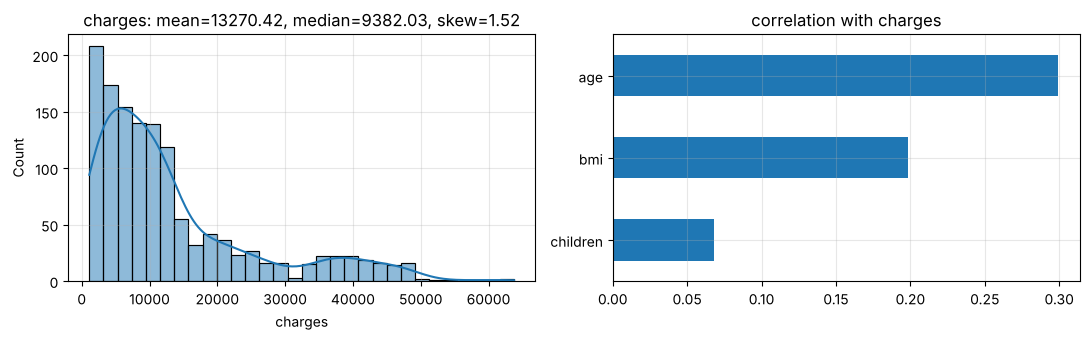

✍️ ตัวแปรตัวเลขที่สัมพันธ์กับ target มากสุด: age (r=0.299), bmi (r=0.198), children (r=0.068)
ค่าเฉลี่ย charges ตาม sex: {'female': 12569.58, 'male': 13956.75}
ค่าเฉลี่ย charges ตาม smoker: {'no': 8434.27, 'yes': 32050.23}
ค่าเฉลี่ย charges ตาม region: {'northeast': 13406.38, 'northwest': 12417.58, 'southeast': 14735.41, 'southwest': 12346.94}


In [3]:
df = load_data(DATA_PATH)
check(df, TARGET)
X, y = make_xy(df, task="regression")
if FEATURES:
    X = X[FEATURES]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(y, kde=True, ax=ax[0]); ax[0].set_title(f"{TARGET}: mean={y.mean():.2f}, median={y.median():.2f}, skew={y.skew():.2f}")
corr_t = pd.concat([X[num_cols(X)], y], axis=1).corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr_t.plot(kind="barh", ax=ax[1], title=f"correlation with {TARGET}"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()
print("✍️ ตัวแปรตัวเลขที่สัมพันธ์กับ target มากสุด:", ", ".join(f"{k} (r={v:.3f})" for k, v in corr_t.head(3).items()))
for c in cat_cols(X):
    print(f"ค่าเฉลี่ย {TARGET} ตาม {c}:", df.groupby(c)[TARGET].mean().round(2).to_dict())

## §2 แบ่ง train/test (fit ทุกอย่างบน train)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
print(f"train {X_train.shape} | test {X_test.shape}")

train (1070, 6) | test (268, 6)


## §3 Simple linear regression: $\hat y = b_0 + b_1 x$
$b_1$ = ความชัน (x เพิ่ม 1 หน่วย ŷ เปลี่ยน $b_1$) · $b_0$ = ค่า ŷ เมื่อ x = 0

สมการ: charges = 3876.9287 + (240.5966) × age
✍️ age เพิ่ม 1 หน่วย → charges เปลี่ยน +240.5966 หน่วยโดยเฉลี่ย
test: {'MAE': 9173.2582, 'MSE': 135983957.4805, 'RMSE': 11661.216, 'R2': 0.1241}


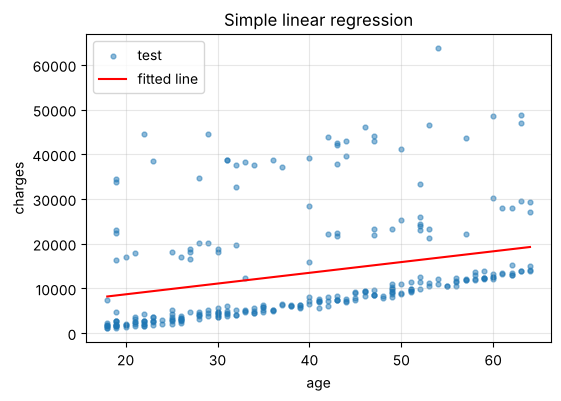

In [5]:
if SIMPLE_X:
    slr = LinearRegression().fit(X_train[[SIMPLE_X]], y_train)
    b0, b1 = slr.intercept_, slr.coef_[0]
    pred_s = slr.predict(X_test[[SIMPLE_X]])
    print(f"สมการ: {TARGET} = {b0:.4f} + ({b1:.4f}) × {SIMPLE_X}")
    print(f"✍️ {SIMPLE_X} เพิ่ม 1 หน่วย → {TARGET} เปลี่ยน {b1:+.4f} หน่วยโดยเฉลี่ย")
    print("test:", {k: round(v, 4) for k, v in reg_metrics(y_test, pred_s).items()})
    plt.figure(figsize=(6, 4)); plt.scatter(X_test[SIMPLE_X], y_test, s=12, alpha=.5, label="test")
    xs = np.linspace(X[SIMPLE_X].min(), X[SIMPLE_X].max(), 50); plt.plot(xs, b0 + b1 * xs, "r", label="fitted line")
    plt.xlabel(SIMPLE_X); plt.ylabel(TARGET); plt.legend(); plt.title("Simple linear regression"); plt.show()

## §4 Multiple linear regression — สมการเต็ม + coefficient (หน่วยเดิม → ตีความได้)
- coefficient ตัวเลข: *x เพิ่ม 1 หน่วย ŷ เปลี่ยน b หน่วย **โดยตัวแปรอื่นคงที่***
- coefficient dummy (เช่น `smoker_yes`): *กลุ่มนี้มี ŷ ต่างจาก **กลุ่มอ้างอิง** (dummy ที่ถูกตัด) b หน่วย*
- **เทียบความสำคัญ** ด้วย coefficient หน่วยเดิมไม่ได้ (หน่วยต่างกัน) → ดู standardized coefficient

In [6]:
prep_raw = build_prep(X_train, scale=None)
if DROP_FIRST:
    prep_raw.set_params(cat__encode=OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
lr = Pipeline([("prep", prep_raw), ("model", LinearRegression())]).fit(X_train, y_train)
names = lr.named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame({"coefficient": lr.named_steps["model"].coef_}, index=names)

# standardized coefficient (z-score feature ตัวเลข; dummy คงเดิม) → ใช้จัดอันดับความสำคัญของตัวเลข = ผลต่อ y เมื่อ x เปลี่ยน 1 SD
prep_std = build_prep(X_train, scale="standard")
if DROP_FIRST:
    prep_std.set_params(cat__encode=OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
lr_std = Pipeline([("prep", prep_std), ("model", LinearRegression())]).fit(X_train, y_train)
std_coef = pd.Series(lr_std.named_steps["model"].coef_, index=lr_std.named_steps["prep"].get_feature_names_out())
coef["standardized_coef"] = std_coef.reindex(coef.index)
coef = coef.reindex(coef["coefficient"].abs().sort_values(ascending=False).index)
display(coef)
b0 = lr.named_steps["model"].intercept_
print("สมการ:\n  " + TARGET + f" = {b0:.4f} " + " ".join(f"{'+' if v >= 0 else '-'} {abs(v):.4f}×{k}" for k, v in coef["coefficient"].items()))
if DROP_FIRST and cat_cols(X):
    print("กลุ่มอ้างอิง (dummy ที่ถูกตัด):", {c: cats[0] for c, cats in zip(cat_cols(X_train), lr.named_steps["prep"].named_transformers_["cat"].named_steps["encode"].categories_)})
top = coef["standardized_coef"].abs().sort_values(ascending=False).index[0]
print(f"✍️ ตัวแปรที่มีผลมากสุด (standardized) = {top} · coefficient หน่วยเดิม {coef.loc[top, 'coefficient']:+.4f}")

,coefficient,standardized_coef
smoker_yes,"23,651.1289","23,651.1289"
region_southwest,-809.7994,-809.7994
region_southeast,-657.8643,-657.8643
children,425.2788,516.8902
region_northwest,-370.6773,-370.6773
bmi,337.0926,"2,036.2281"
age,256.9757,"3,614.9754"
sex_male,-18.5917,-18.5917


สมการ:
  charges = -11931.2191 + 23651.1289×smoker_yes - 809.7994×region_southwest - 657.8643×region_southeast + 425.2788×children - 370.6773×region_northwest + 337.0926×bmi + 256.9757×age - 18.5917×sex_male
กลุ่มอ้างอิง (dummy ที่ถูกตัด): {'sex': 'female', 'smoker': 'no', 'region': 'northeast'}
✍️ ตัวแปรที่มีผลมากสุด (standardized) = smoker_yes · coefficient หน่วยเดิม +23651.1289


**✍️ คำตอบ §4:** สมการ ŷ = … · `…` เพิ่ม 1 หน่วย ŷ เพิ่ม … โดยตัวแปรอื่นคงที่ · `smoker_yes` = … → คนสูบบุหรี่จ่ายมากกว่าคนไม่สูบ … หน่วย

## §5 Evaluation: mean baseline vs simple vs multiple (MAE / MSE / RMSE / R²)
MAE = |error| เฉลี่ย (หน่วยเดียวกับ y) · RMSE = ลงโทษ error ใหญ่มากกว่า · R² = สัดส่วนความแปรปรวนของ y ที่อธิบายได้ (1 = สมบูรณ์, 0 = เท่ากับทายค่าเฉลี่ย, < 0 = แย่กว่าค่าเฉลี่ย)

In [7]:
models = {"Mean baseline": DummyRegressor(strategy="mean"),
          "Linear Regression (all)": lr}
if SIMPLE_X:
    models[f"Linear Regression ({SIMPLE_X})"] = Pipeline([("sel", ColumnTransformer([("x", "passthrough", [SIMPLE_X])])), ("model", LinearRegression())])
rows = []
for name, m in models.items():
    if EVAL_MODE == "holdout":
        m.fit(X_train, y_train)
        r = {"model": name, **reg_metrics(y_test, m.predict(X_test)), "train_R2": r2_score(y_train, m.predict(X_train))}
    else:
        r = evaluate_reg(name, m, X, y)
    rows.append(r)
mt = results_table(rows)
say_compare(mt, "RMSE", "Mean baseline", higher_is_better=False)
best_r2 = mt.loc[mt["R2"].idxmax()]
print(f"✍️ R² = {best_r2['R2']:.4f} → โมเดลอธิบายความแปรปรวนของ {TARGET} ได้ {best_r2['R2']:.1%} · MAE {best_r2['MAE']:.2f} = ทายพลาดเฉลี่ย ±{best_r2['MAE']:.2f} หน่วย")

,model,MAE,MSE,RMSE,R2,train_R2
0,Mean baseline,"9,593.3385","155,391,443.6846","12,465.6104",-0.0009,0.0000
1,Linear Regression (all),"4,181.1945","33,596,915.8514","5,796.2847",0.7836,0.7417
2,Linear Regression (age),"9,173.2582","135,983,957.4805","11,661.2160",0.1241,0.0794


✍️ โมเดลที่ดีที่สุดตาม RMSE คือ Linear Regression (all) ได้ RMSE = 5796.2847 เทียบกับ baseline (Mean baseline) ที่ได้ 12465.6104 ต่างกัน -6669.3258
✍️ R² = 0.7836 → โมเดลอธิบายความแปรปรวนของ charges ได้ 78.4% · MAE 4181.19 = ทายพลาดเฉลี่ย ±4181.19 หน่วย


,actual,predicted,error,|error|,error²
0,"9,095.0683","8,969.5503",125.5180,125.5180,"15,754.7622"
1,"5,272.1758","7,068.7474","-1,796.5716","1,796.5716","3,227,669.6680"
2,"29,330.9832","36,858.4109","-7,527.4278","7,527.4278","56,662,168.7053"
3,"9,301.8936","9,454.6785",-152.7850,152.7850,"23,343.2411"
4,"33,750.2918","26,973.1735","6,777.1183","6,777.1183","45,929,333.0409"


(5 แถวนี้) MAE = 3275.8841 · MSE = 21171653.8835 · RMSE = 4601.2666


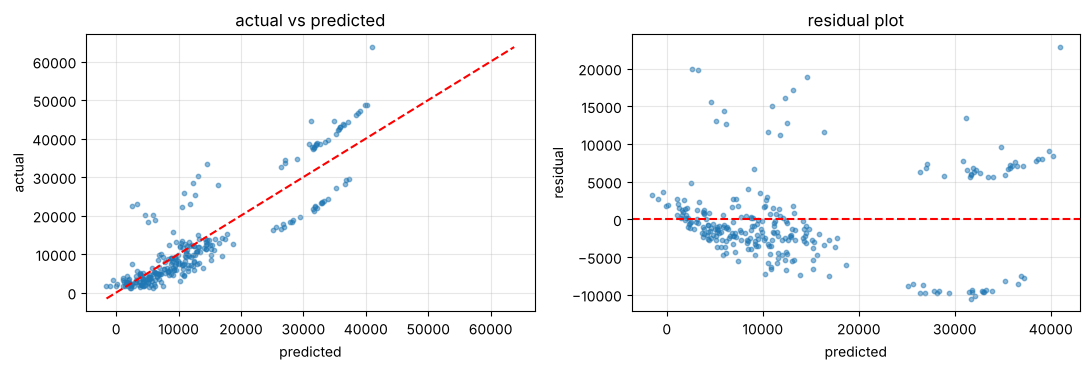

✍️ residual ควรกระจายสุ่มรอบ 0 · ถ้าเป็นรูปแบบ (โค้ง/กรวย/แยกกลุ่ม) แปลว่าความสัมพันธ์ไม่เป็นเชิงเส้นหรือขาดตัวแปร/interaction


In [8]:
# ตรวจด้วยมือ: 5 แถวแรกของ test
pred = lr.predict(X_test)
chk = pd.DataFrame({"actual": y_test.values[:5], "predicted": pred[:5]}); chk["error"] = chk.actual - chk.predicted
chk["|error|"] = chk.error.abs(); chk["error²"] = chk.error ** 2
display(chk)
print(f"(5 แถวนี้) MAE = {chk['|error|'].mean():.4f} · MSE = {chk['error²'].mean():.4f} · RMSE = {np.sqrt(chk['error²'].mean()):.4f}")
# Residual plot + actual vs predicted
res = y_test - pred
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(pred, y_test, s=10, alpha=.5); lim = [min(pred.min(), y_test.min()), max(pred.max(), y_test.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set(xlabel="predicted", ylabel="actual", title="actual vs predicted")
ax[1].scatter(pred, res, s=10, alpha=.5); ax[1].axhline(0, color="r", ls="--"); ax[1].set(xlabel="predicted", ylabel="residual", title="residual plot")
plt.tight_layout(); plt.show()
print("✍️ residual ควรกระจายสุ่มรอบ 0 · ถ้าเป็นรูปแบบ (โค้ง/กรวย/แยกกลุ่ม) แปลว่าความสัมพันธ์ไม่เป็นเชิงเส้นหรือขาดตัวแปร/interaction")

## §6 เทียบโมเดล regression อื่น + optimize (CV บน train)

In [9]:
cvr = get_cv("regression")
cands = {"Mean baseline": DummyRegressor(),
         "Linear Regression": make_pipe(LinearRegression(), X_train),
         "KNN regressor (k=5)": make_pipe(KNeighborsRegressor(5), X_train),
         "Decision Tree reg (depth=5)": make_pipe(DecisionTreeRegressor(max_depth=5, random_state=SEED), X_train, scale=None),
         "Random Forest reg": make_pipe(RandomForestRegressor(n_estimators=200, random_state=SEED), X_train, scale=None)}
rows = [evaluate_reg(n, m, X_train, y_train, cvr) for n, m in cands.items()]
g_knn = GridSearchCV(make_pipe(KNeighborsRegressor(), X_train), {"model__n_neighbors": range(1, 31), "model__weights": ["uniform", "distance"]},
                     cv=cvr, scoring="neg_root_mean_squared_error").fit(X_train, y_train)
g_tree = GridSearchCV(make_pipe(DecisionTreeRegressor(random_state=SEED), X_train, scale=None),
                      {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "model__min_samples_leaf": [1, 5, 10, 20]},
                      cv=cvr, scoring="neg_root_mean_squared_error").fit(X_train, y_train)
rows += [evaluate_reg("KNN optimized", g_knn.best_estimator_, X_train, y_train, cvr, str(g_knn.best_params_)),
         evaluate_reg("Tree optimized", g_tree.best_estimator_, X_train, y_train, cvr, str(g_tree.best_params_))]
ct = results_table(rows, sort_by="RMSE", ascending=True)
say_compare(ct, "RMSE", "Mean baseline", higher_is_better=False)

best_name = ct.iloc[0]["model"]
best_model = {**cands, "KNN optimized": g_knn.best_estimator_, "Tree optimized": g_tree.best_estimator_}[best_name]
best_model.fit(X_train, y_train)
print(f"โมเดลที่ดีที่สุด ({best_name}) บน test:", {k: round(v, 4) for k, v in reg_metrics(y_test, best_model.predict(X_test)).items()})

,model,settings,MAE,MSE,RMSE,R2
0,Tree optimized,"{'model__max_depth': 4, 'model__min_samples_le...","2,726.7153","21,306,458.1901","4,615.8919",0.8534
1,Decision Tree reg (depth=5),,"2,743.7213","23,411,581.4104","4,838.5516",0.8384
2,Random Forest reg,,"2,755.6307","24,216,951.9868","4,921.0722",0.8330
3,KNN optimized,"{'model__n_neighbors': 4, 'model__weights': 'd...","3,385.3908","33,344,707.6655","5,774.4877",0.7697
4,KNN regressor (k=5),,"3,654.6603","35,439,172.1010","5,953.0809",0.7543
5,Linear Regression,,"4,234.9836","37,737,178.5615","6,143.0594",0.7389
6,Mean baseline,,"9,007.0935","144,543,775.3428","12,022.6360",-0.0042


✍️ โมเดลที่ดีที่สุดตาม RMSE คือ Tree optimized ({'model__max_depth': 4, 'model__min_samples_leaf': 10}) ได้ RMSE = 4615.8919 เทียบกับ baseline (Mean baseline) ที่ได้ 12022.6360 ต่างกัน -7406.7440
โมเดลที่ดีที่สุด (Tree optimized) บน test: {'MAE': 2697.7654, 'MSE': 21093484.0046, 'RMSE': 4592.7643, 'R2': 0.8641}


**✍️ คำตอบ §6:** โมเดลที่ดีที่สุดคือ … (CV RMSE …, R² …) ดีกว่า Linear Regression (RMSE …) เพราะ … (เช่น ความสัมพันธ์ไม่เชิงเส้น/มี interaction) · optimize แล้ว RMSE ลดจาก … เป็น …

## §7 ทำนายข้อมูลใหม่

In [10]:
if NEW_DATA is not None:
    nd = align_new(new_data(NEW_DATA), X)
    out = nd.copy()
    out["pred_LinearRegression"] = lr.predict(nd)
    out[f"pred_{best_name}"] = best_model.predict(nd)
    display(out)
    # ตรวจมือ: แทนค่าในสมการ
    row = lr.named_steps["prep"].transform(nd.iloc[[0]])[0]
    terms = " + ".join(f"({c:.3f}×{v:g})" for c, v in zip(lr.named_steps["model"].coef_, row))
    print(f"แทนค่า: {lr.named_steps['model'].intercept_:.3f} + {terms} = {lr.predict(nd.iloc[[0]])[0]:.4f}")

,age,sex,bmi,children,smoker,region,pred_LinearRegression,pred_Tree optimized
0,40,male,30.0000,2,no,northeast,"9,292.5516","7,377.6988"


แทนค่า: -11931.219 + (256.976×40) + (337.093×30) + (425.279×2) + (-18.592×1) + (23651.129×0) + (-370.677×0) + (-657.864×0) + (-809.799×0) = 9292.5516


**✍️ คำตอบ §7:** ข้อมูลใหม่ทำนาย {TARGET} = … (Linear Regression) / … (…)